In [14]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df = gpd.read_file("../data/processed/stops_with_routes.gpkg")
df = df.to_crs(epsg=2180)
buffers = gpd.GeoDataFrame(
    df[["stop_id"]].copy(),
    geometry=df.geometry.buffer(500),
    crs = df.crs

)

close_stops = gpd.sjoin(buffers,df,rsuffix="buffer",lsuffix="")
close_stops.head()

,stop_id_,geometry,index_buffer,stop_id_buffer,stop_code,stop_name,stop_desc,stop_lat,stop_lon,number_of_routes
0,stop_1_1,"POLYGON ((576277.327 247209.499, 576274.919 24...",173,stop_274_46619,5-01,PH,1,50.084174,20.064555,NaN
0,stop_1_1,"POLYGON ((576277.327 247209.499, 576274.919 24...",0,stop_1_1,920-01,Grodzki Urząd Pracy,1,50.087300,20.059600,1.0
0,stop_1_1,"POLYGON ((576277.327 247209.499, 576274.919 24...",1,stop_1_2,920-02,Grodzki Urząd Pracy,2,50.087400,20.059700,1.0
0,stop_1_1,"POLYGON ((576277.327 247209.499, 576274.919 24...",169,stop_272_46419,194-01,Elektromontaż,1,50.087682,20.064594,1.0
0,stop_1_1,"POLYGON ((576277.327 247209.499, 576274.919 24...",170,stop_272_46429,194-02,Elektromontaż,2,50.087727,20.064095,1.0


In [18]:
neighbors = close_stops[close_stops["stop_id_buffer"] != close_stops["stop_id_"]]

counts = neighbors.groupby("stop_id_buffer").size()
counts.head()

stop_id_buffer
stop_1076_317419    1
stop_1076_317429    1
stop_10_3           6
stop_10_33          6
stop_10_34          6
dtype: int64

In [23]:
df["nearby_stops_500m"] = (
    df["stop_id"].map(counts).fillna(0).astype(int)
)
df.head()
#df.to_file("../data/processed/stops_with_routes.gpkg",driver="GPKG")

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,number_of_routes,geometry,nearby_stops_500m
0,stop_1_1,920-01,Grodzki Urząd Pracy,1,50.087300,20.059600,1.0,POINT (575777.327 247209.499),6
1,stop_1_2,920-02,Grodzki Urząd Pracy,2,50.087400,20.059700,1.0,POINT (575784.321 247220.715),6
2,stop_2_4,561-01,Kościuszkowców,1,50.016651,19.929831,3.0,POINT (566594.751 239233.295),7
3,stop_2_5,561-02,Kościuszkowców,2,50.015661,19.929342,3.0,POINT (566561.097 239122.822),4
4,stop_3_6,743-01,Solvay,1,50.014606,19.927852,3.0,POINT (566455.838 239004.235),4


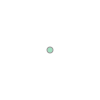

In [31]:
from shapely.geometry import Point

krk_center = Point(19.9383, 50.0613)
center_gpd = gpd.GeoSeries([krk_center],crs="EPSG:4326")
center_gpd = center_gpd.to_crs("EPSG:2180")
krk_center = center_gpd.iloc[0]
krk_center

In [34]:
df["distance_to_center"] = df.geometry.distance(krk_center)
df["distance_to_center"].describe()

count      355.000000
mean      4294.789156
std       2750.528367
min        241.599406
25%       1993.800831
50%       3905.960023
75%       5930.559552
max      12843.030236
Name: distance_to_center, dtype: float64

In [36]:
features = [
    "number_of_routes",
    "nearby_stops_500m",
    "distance_to_center"
]
df[features].describe()
df[features].isna().sum()

,number_of_routes,nearby_stops_500m,distance_to_center
count,353.0000,355.000000,355.000000
mean,4.0000,4.619718,4294.789156
std,1.6855,2.605764,2750.528367
min,1.0000,0.000000,241.599406
25%,3.0000,3.000000,1993.800831
50%,4.0000,4.000000,3905.960023
75%,5.0000,6.000000,5930.559552
max,10.0000,16.000000,12843.030236


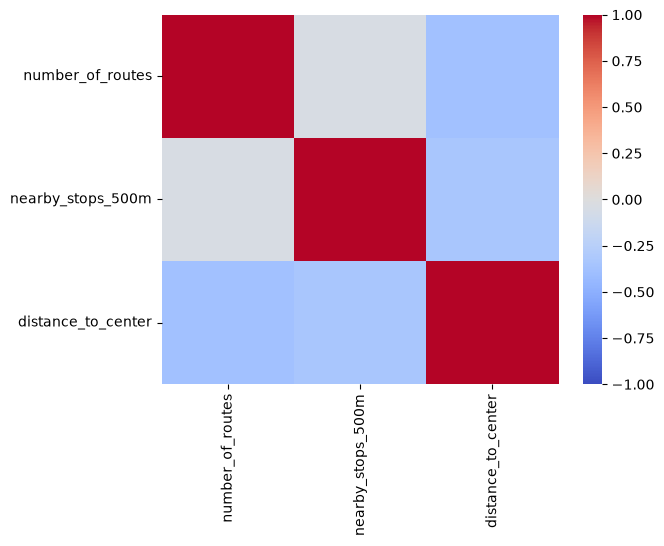

In [39]:
corr_matrix = df[features].corr()
corr_matrix

import seaborn as sns

sns.heatmap(corr_matrix,cmap="coolwarm",vmin=-1,vmax=1)
plt.show()

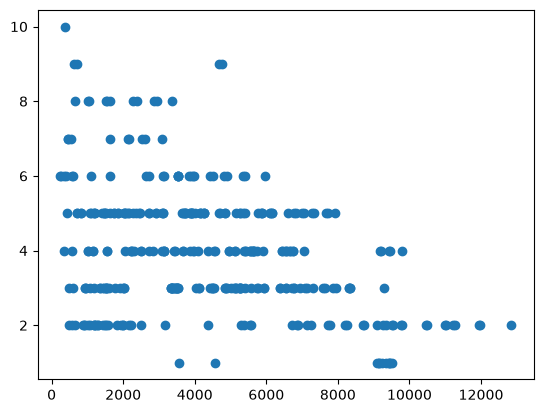

In [40]:
plt.scatter(df["distance_to_center"],df["number_of_routes"])
plt.show()

In [42]:
df.to_file("../data/processed/stops_spatial.gpkg",driver="GPKG")